In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("StudentPerformanceFactors.csv")

## 1. Inspecting the data

In [98]:
df.head(10)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,Low,Medium,Private,Neutral,2,No,High School,Moderate,Male,67
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,High,High,Public,Negative,2,No,High School,Far,Male,66
8,17,94,Medium,High,No,6,80,High,Yes,0,Medium,Low,Private,Neutral,1,No,College,Near,Male,69
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,High,High,Public,Positive,5,No,High School,Moderate,Male,72


In [100]:
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

so we do have null values in 3 columns that are `Teaching_Quality`, `Parental_Education_Level`, and `Distance_from_Home`. i will be droping those enteries since they aren't much in number anyways. 

In [106]:
df = df.dropna(subset=["Teacher_Quality", "Parental_Education_Level", "Distance_from_Home"])

now to check for invalid data enteries like negative sleep hours or more than 100 score. 

In [ ]:
for col in ["Attendance", "Exam_Score", "Previous_Scores"]:
    print((~df[col].between(0,100)).sum())

print((df["Sleep_Hours"]<0).sum())
print()

0
1
0
0


so there is only one invalid entry in exam score so i will just use a boolean mask and drop those specific entries (here only one) where the exam score is more than 100.

In [124]:
df = df[df["Exam_Score"]<=100]

In [125]:
for col in df.select_dtypes(include=["object", "string"]).columns:
    print(col, df[col].unique().tolist())

Parental_Involvement ['Low', 'Medium', 'High']
Access_to_Resources ['High', 'Medium', 'Low']
Extracurricular_Activities ['No', 'Yes']
Motivation_Level ['Low', 'Medium', 'High']
Internet_Access ['Yes', 'No']
Family_Income ['Low', 'Medium', 'High']
Teacher_Quality ['Medium', 'High', 'Low']
School_Type ['Public', 'Private']
Peer_Influence ['Positive', 'Negative', 'Neutral']
Learning_Disabilities ['No', 'Yes']
Parental_Education_Level ['High School', 'College', 'Postgraduate']
Distance_from_Home ['Near', 'Moderate', 'Far']
Gender ['Male', 'Female']


so there is no column in categorical data either where the entry is out of the normal expected entries.

## 2. Visualisation of data

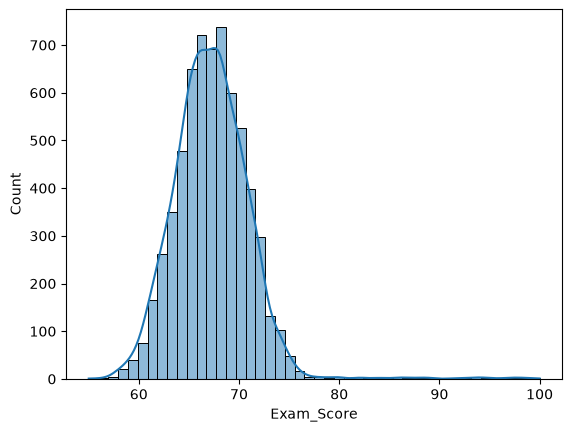

In [130]:
sns.histplot(data=df, x="Exam_Score", bins=46, kde=True)
plt.show()

most of the marks are centered around 65-70. hence that should be the media score range

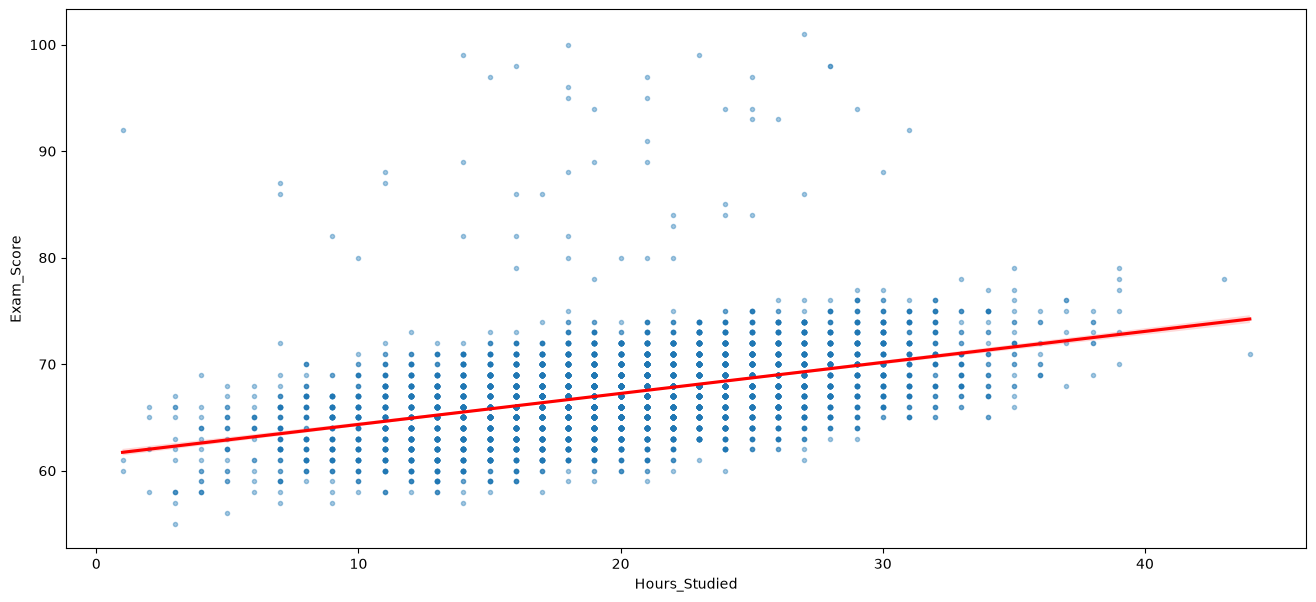

In [ ]:
plt.figure(figsize=(16,7))
sns.regplot(data=df, x="Hours_Studied", y="Exam_Score",
            scatter_kws={"alpha":0.4, "s":8.9}, line_kws={"color":"red"})
plt.show()

the plot with hours studied do show a linear relation with exam score with some outliers.

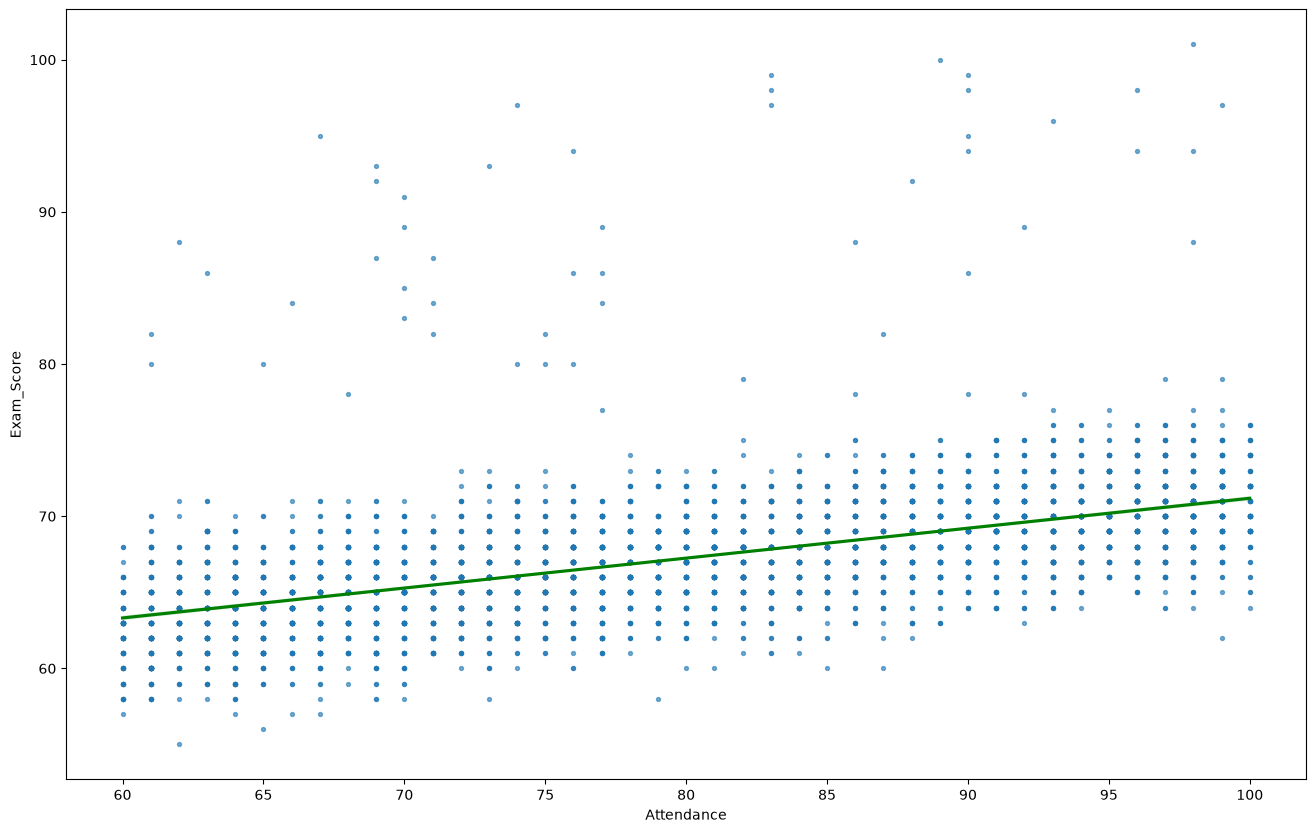

In [110]:
plt.figure(figsize=(16,10))
sns.regplot(data=df, x="Attendance", y="Exam_Score", 
            scatter_kws={"alpha":0.6, "s":8}, line_kws={"color":"green"})
plt.show()

the linear relation is somewhat prevalent, lower than hours of study but still very much relevant.  

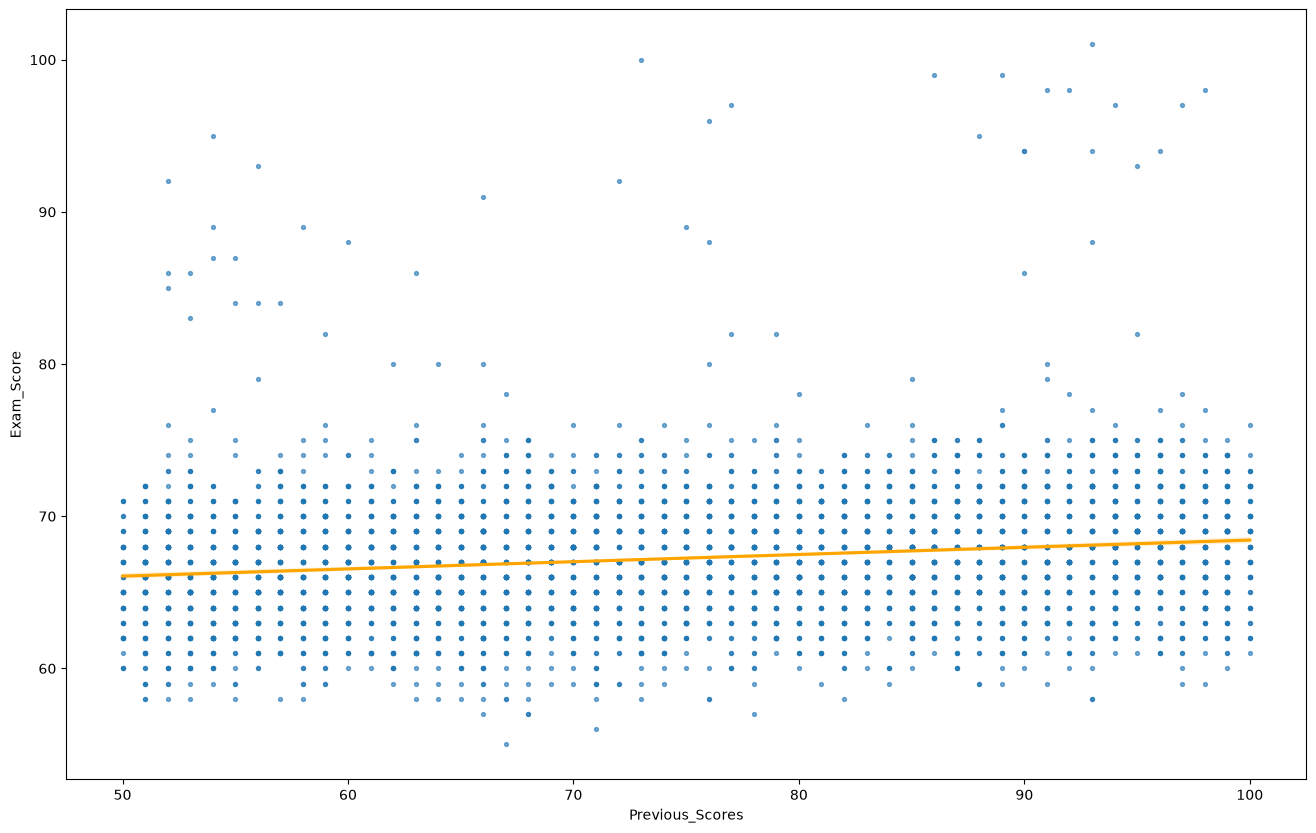

In [111]:
plt.figure(figsize=(16,10))
sns.regplot(data=df, x="Previous_Scores", y="Exam_Score", 
            scatter_kws={"alpha":0.6, "s":8}, line_kws={"color":"orange"})
plt.show()

a very strong relationship can not be established by this plot. the spread is more or less evenly distributed. and similar was the case for attendance too i suppose.

<Axes: xlabel='Parental_Involvement', ylabel='Exam_Score'>

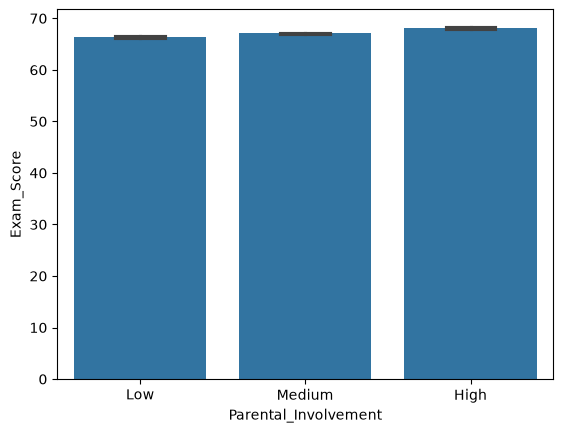

In [112]:
order = ["Low", "Medium", "High"]
sns.barplot(data=df, x="Parental_Involvement", y="Exam_Score",
            order=order, errorbar=("ci", 95), capsize=0.3)

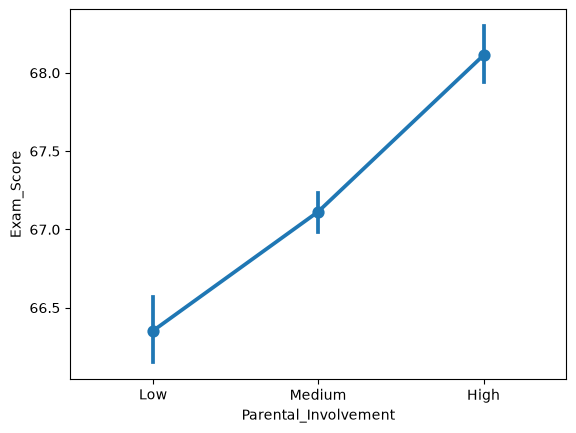

In [131]:
sns.pointplot(data=df, x="Parental_Involvement", y="Exam_Score")
plt.show()

there is a clear correlation between mean exam scores and parental involvement. high parental involvement corresponds to higher mean marks. the difference is however not so significant but still present. 

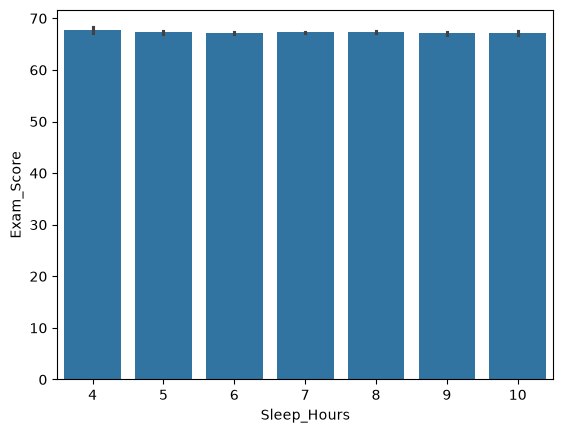

In [114]:
sns.barplot(data=df, x="Sleep_Hours", y="Exam_Score", errorbar=("ci", 95))
plt.show()

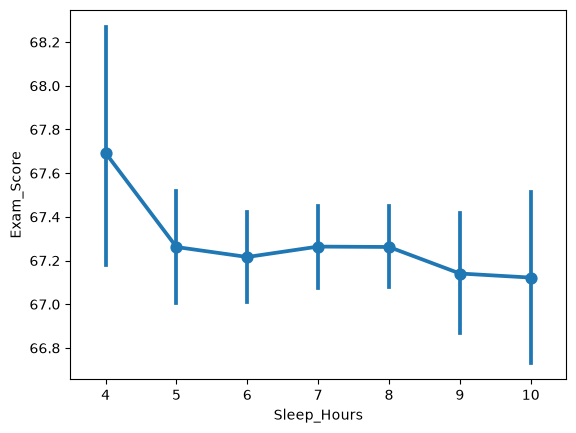

In [115]:
sns.pointplot(data=df, x="Sleep_Hours", y="Exam_Score")
plt.show()

since the uncertainity in the mean value is too much, that is the presence of outliers is too much, nothing significanlty meaningful can be inferred form the plot. the effect of sleep hours remains very small on the exam score 

## 3. Preprocessing the data

In [132]:
feature_cols = [col for col in df.keys()[:-1]]
X = df[feature_cols]
y = df["Exam_Score"]

X.shape, y.shape

((6377, 19), (6377,))